# Figure3 Event Diagnostics

Reproduces panels used in the main manuscript. Generated files are written to `logs/scripts/figure3_event_diagnostics/`.


# S6.4.2 Representative event analyses

Six event-withholding forecasts and fixed-trajectory diagnostics for representative El Niño and La Niña events.


In [1]:
import os, sys
from pathlib import Path

if Path(os.getcwd()).stem == 'scripts':
    ROOT = Path(os.getcwd()).parent
else:
    ROOT = Path(os.getcwd())

sys.path.append(str(ROOT))
os.chdir(ROOT)


In [2]:
import re
import sys
import json
import yaml
import shlex
import random
import dotenv
import signal
import logging
import datetime
import nd2py as nd
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from socket import gethostname
from argparse import Namespace
from argparse import ArgumentParser
from nd2py.utils import init_logger
from setproctitle import setproctitle
from src.utils import add_negation_flags, tag2ansi, log_exception
from src.core import Triplet, Individual
from src.assistant import Assistant
from src.ai_scientist import AIScientist
from src.ai_scientist_parallel import AIScientistParallel
from src.utils import wrap_ansi

import warnings
# warnings.simplefilter('error', RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="nd2py")

dotenv.load_dotenv()
_logger = logging.getLogger('src')

args = Namespace(**json.load(open('data/cache/default_args.json', 'r')))
args.save_dir = './logs/scripts'
args.exp_name = 'figure3_event_diagnostics'
args.train_period = ['all', 'all']
args.test_period = ['all', 'all']
args.a_skill_after_2004 = 0.0

## Build Save Path
if args.exp_name is None:
    now = datetime.now()
    date = now.strftime("%Y%m%d")
    curr = now.strftime("%H%M%S")
    host = gethostname()
    exp_name = f'{date}_{args.name}_{curr}_{host}'
    exp_name = re.compile(r'[ <>:"/\\|?*\x00-\x1f]').sub('_', exp_name.strip())
    exp_name = exp_name or 'unnamed'
    exp_name = exp_name[:255] # Max filename length on most filesystems
    args.exp_name = exp_name
save_path = Path(args.save_dir) / args.exp_name
if not save_path.exists():
    save_path.mkdir(parents=True, exist_ok=True)
else:
    _logger.warning(f"Save path {save_path} already exists.")
args.save_path = str(save_path)

## Set Random State
if args.random_state is None:
    args.random_state = random.randint(0, 2**31 - 1)
## Set Command
args.command = ' '.join(map(shlex.quote, [sys.executable, *sys.argv]))

args.debug = True

## Init Logger
init_logger(
    "src", 
    exp_name=args.exp_name, 
    log_file=save_path / "info.log", 
    info_level='debug' if args.debug else 'info',
    show_lineno_for_all_levels=args.debug,
)
nd2py_logger = logging.getLogger("nd2py")
nd2py_logger.setLevel(_logger.level)
nd2py_logger.handlers = _logger.handlers.copy()

## Save Args
args_path = save_path / "args.json"
if args_path.exists():
    i = 1
    while args_path.with_suffix(f".json.{i}").exists(): i += 1
    args_path.rename(args_path.with_suffix(f".json.{i}"))
    _logger.warning(f"args.json already exists, backup to args.json.{i}")
_logger.note(f"Args: {args}")
with open(args_path, "w") as f:
    json.dump(vars(args), f, indent=4, ensure_ascii=False)

# Start the main process
setproctitle(f"{args.exp_name}@ZihanYu")

## Load Assistant
assistant = Assistant(args)
## Load Data
# 加载变量
variables = assistant.load_variables()
# 加载数据
df_all = assistant.load_data(normalize_co2=False)
# 划分数据
if True:
    train_start, train_end = args.train_period
    test_start, test_end = args.test_period
    train_start = pd.Period(train_start, freq='M') if train_start != 'all' else df_all.index[0]
    train_end = pd.Period(train_end, freq='M') if train_end != 'all' else df_all.index[-1]
    test_start = pd.Period(test_start, freq='M') if test_start != 'all' else df_all.index[0]
    test_end = pd.Period(test_end, freq='M') if test_end != 'all' else df_all.index[-1]
    df_train = df_all.loc[train_start:train_end]
    df_test = df_all.loc[test_start:test_end]
elif False:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
else:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=1999, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=2000, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
# 准备拓扑
edge_list, num_nodes = assistant.load_topology()
# 打印日志
_logger.info(
    f"Data loaded: {len(df_all)} samples, "
    f"where {len(df_train)}({len(df_train)/len(df_all):.2%}) "
    f"from {df_train.index[0]} to {df_train.index[-1]} for training, "
    f"and {len(df_test)}({len(df_test)/len(df_all):.2%}) "
    f"from {df_test.index[0]} to {df_test.index[-1]} for testing."
)
_logger.info(
    f"Variables: " + ", ".join(f'{var_name}({len(sub_df)})' for var_name, sub_df in df_all.T.groupby(level=0)) + "."
)
## Load Seed Individuals
seed_individuals = assistant.load_seed_individuals()

## Initialize Runner
Runner = AIScientistParallel if args.parallel else AIScientist
kwargs = dict(
    args=args,
    assistant=assistant,
    variables=variables,
    binary=[
        getattr(nd, name) for name in args.binary
        # nd.Add, nd.Sub, nd.Mul, nd.Div
    ],
    unary=[
        getattr(nd, name) for name in args.unary
        # nd.Sin, nd.Cos,
        # nd.Exp, nd.LogAbs,
        # nd.Sigmoid, nd.Tanh,
        # nd.Pow2, nd.Pow3, nd.SqrtAbs,
        # nd.Aggr, nd.Readout, nd.Sour, nd.Targ,
    ],
    edge_list=edge_list,
    num_nodes=num_nodes,
    seed_individuals=seed_individuals,
)
_logger.note(f"Initializing Runner with args: {kwargs}")
est = Runner(**kwargs)
# Set Clip Bounds
est.evaluator.simulator.set_clip_bounds(df_all, clip_factor=args.clip_factor)


Save path logs/scripts/figure3_event_diagnostics already exists.
[figure3_event_diagnostics|src|W|Oct15 10:42:11|0:00:00.002484] (../../../../../../tmp/ipykernel_2316555/3526246676.py:86) args.json already exists, backup to args.json.3
[figure3_event_diagnostics|src|N|Oct15 10:42:11|0:00:00.004311] (../ClimateModelCode/nd2py_package/nd2py/utils/logger.py:62) Args: Namespace(name='Reduce_320_230_368', setting='only_co2', exp_name='figure3_event_diagnostics', llm_model=None, llm_provider=None, seed_individuals=['co2_320_230_368'], load_seed_individuals=[], use_seed_individuals_only=True, num_workers=24, parallel=True, timeout=240, population_size=200, n_iter=300, programs_per_prompt=2, generate_per_prompt=8, expire_iter=1, keep_best=False, random_state=1581316702, score_func='tanh', a_rmse=0.0, a_trajrmse=0.0, a_skill_cv_sum=0.0, a_skill_cv_sum_inner=0.0, a_skill_cv_mean=0.0, a_ENSO_skill_cv=1.0, a_Total_skill_cv=10.0, a_skill_sum_inner=0.0, a_skill_sum=0.0, a_skill_mean=0.0, a_ENSO_skil

In [3]:
args.a_rmse = 0.0
args.a_trajrmse = 0.0
args.a_skill_cv_sum = 0.0
args.a_skill_cv_sum_inner = 0.0
args.a_skill_cv_mean = 0.0
args.a_ENSO_skill_cv = 1.0
args.a_ATL3_skill_cv = 1.0
args.a_SASD_skill_cv = 1.0
args.a_Total_skill_cv = 10.0
args.a_skill_sum_inner = 0.0
args.a_skill_sum = 0.0
args.a_skill_mean = 0.0
args.a_ENSO_skill = 0.0
args.a_IOB_skill = 0.0
args.a_SASD_skill = 0.0
args.a_Total_skill = 0.0
args.a_skill_after_2004 = 1.0
args.a_length = 1.0
args.a_params = 0.0
args.a_std = 0.25
args.a_skewness = 0.25
args.a_spectrum = 0.25
args.a_leadlag = 0.25
args.a_forecast = 0.0
args.a_contain_co2 = 0.0
args.max_month = 40
args.a_correlation_auc_sum = 0.0
args.a_correlation_auc_cv_sum = 0.0

args.damp = 1e-1
args.atol = 1e-6
args.btol = 1e-6
args.iter_lim = None


In [4]:
import seaborn as sns
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from nd2py.utils.plot import get_fig

df_all = assistant.load_data(normalize_co2=False, dropna=True).loc['1979-01':'2024-12'].copy()
args.n_steps = 10

plain_triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = x + mode['ENSO'] * h + log(u_co2) + aggr( sour(x) + tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x)) )
    dh_dt = h + readout(x) ** 2 + aggr( sour(x) + tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x)) )
    return coeff, dx_dt, dh_dt
""")

flagged_triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = Variable('damping_flag') * x + Variable('recharging_flag') * mode['ENSO'] * h + Variable('co2_flag') * log(u_co2) + aggr(Variable('sst_to_sst_flag') * sour(x) + Variable('ohc_to_sst_flag') * tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x)))
    dh_dt = Variable('damping_flag') * h + Variable('Tbar_flag') * readout(x) ** 2 + aggr(Variable('sst_to_ohc_flag') * sour(x) + Variable('ohc_to_ohc_flag') * tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x)))
    return coeff, dx_dt, dh_dt
""")

flagged_xro_triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + sin(t) + cos(t) + sin(2 * t) + cos(2 * t)
    dx_dt = Variable('damping_flag') * x + Variable('recharging_flag') * readout(mode['ENSO'] * h) + Variable('other_sst_flag') * (mode['ENSO'] * x**2 + mode['ENSO'] * x * readout(mode['ENSO'] * h) + mode['IOD'] * x**2 + aggr(sour(x)))
    dh_dt = Variable('damping_flag') * h + Variable('local_sst_flag') * x + Variable('sst_to_ohc_flag') * aggr(sour(x))
    return coeff, dx_dt, dh_dt
""")

def new_individual(triplet):
    return Individual(uuid=None, n_iter=None, source=None, parents=[],
                      program=assistant.triplet_to_program(triplet), triplet=triplet,
                      dynamics=assistant.triplet_to_dynamics(triplet))

def leave5_train(start):
    year = pd.Period(start, freq='M').year
    # Withhold calendar years Y-1,...,Y+3 around initialization year Y.
    return pd.concat([
        df_all.loc[:f'{year-2}-12'],
        df_all.loc[f'{year+4}-01':],
    ])

def event_train(case):
    if 'withhold' not in case:
        return leave5_train(case['start'])
    first, last = case['withhold']
    return pd.concat([
        df_all.loc[:pd.Period(first, freq='M') - 1],
        df_all.loc[pd.Period(last, freq='M') + 1:],
    ])

def fit_individual(triplet, train):
    item = new_individual(triplet)
    item.dynamics, _ = est.evaluator.fitter.fit_parameters(item.dynamics, train, nonlinear=False)
    return item

def rollout(dynamics, start, months):
    initial = df_all.loc[[pd.Period(start, freq='M')]]
    dt = df_all['t'].diff().iloc[1].value
    return est.evaluator.simulator.get_simulation_with_forcing(
        f=dynamics, df=initial[['x', 'h', 't']], dt=dt,
        df_forcing=initial.drop(columns=['x', 'h', 't'], level=0), max_month=months,
    )

cases = [
    {'start': '2022-12', 'months': 24, 'title': '2023/24 El Niño'},
    {'start': '2019-12', 'months': 36, 'title': '2020--2022 triple-dip La Niña'},
    {'start': '1981-12', 'months': 24, 'title': '1982/83 El Niño'},
    {'start': '1996-12', 'months': 24, 'title': '1997/98 El Niño'},
    {'start': '1997-12', 'months': 48, 'title': '1998--2001 triple-dip La Niña', 'withhold': ('1997-01', '2001-12')},
    {'start': '2014-12', 'months': 24, 'title': '2015/16 El Niño'},
]


[figure3_event_diagnostics|data_loader|D|Oct15 10:42:12|0:00:00.522170] (src/assistant/data_loader.py:55) Detrending ENSO SST with coefficients: [-7.14225957e-07  3.27857303e-04  8.16754329e-02]
[figure3_event_diagnostics|data_loader|D|Oct15 10:42:12|0:00:00.524969] (src/assistant/data_loader.py:55) Detrending NPMM SST with coefficients: [ 5.23786876e-06 -5.07198219e-03  1.14418764e+00]
[figure3_event_diagnostics|data_loader|D|Oct15 10:42:12|0:00:00.527134] (src/assistant/data_loader.py:55) Detrending SPMM SST with coefficients: [-6.20970905e-07 -3.72185672e-04  3.92080518e-01]
[figure3_event_diagnostics|data_loader|D|Oct15 10:42:12|0:00:00.529328] (src/assistant/data_loader.py:55) Detrending IOB SST with coefficients: [ 1.84648014e-06 -1.01057274e-03  8.39776510e-02]
[figure3_event_diagnostics|data_loader|D|Oct15 10:42:12|0:00:00.531126] (src/assistant/data_loader.py:55) Detrending IOD SST with coefficients: [-1.41512104e-06  1.72745765e-03 -5.17341840e-01]
[figure3_event_diagnostics|

## Leave-5-year-out forecasts


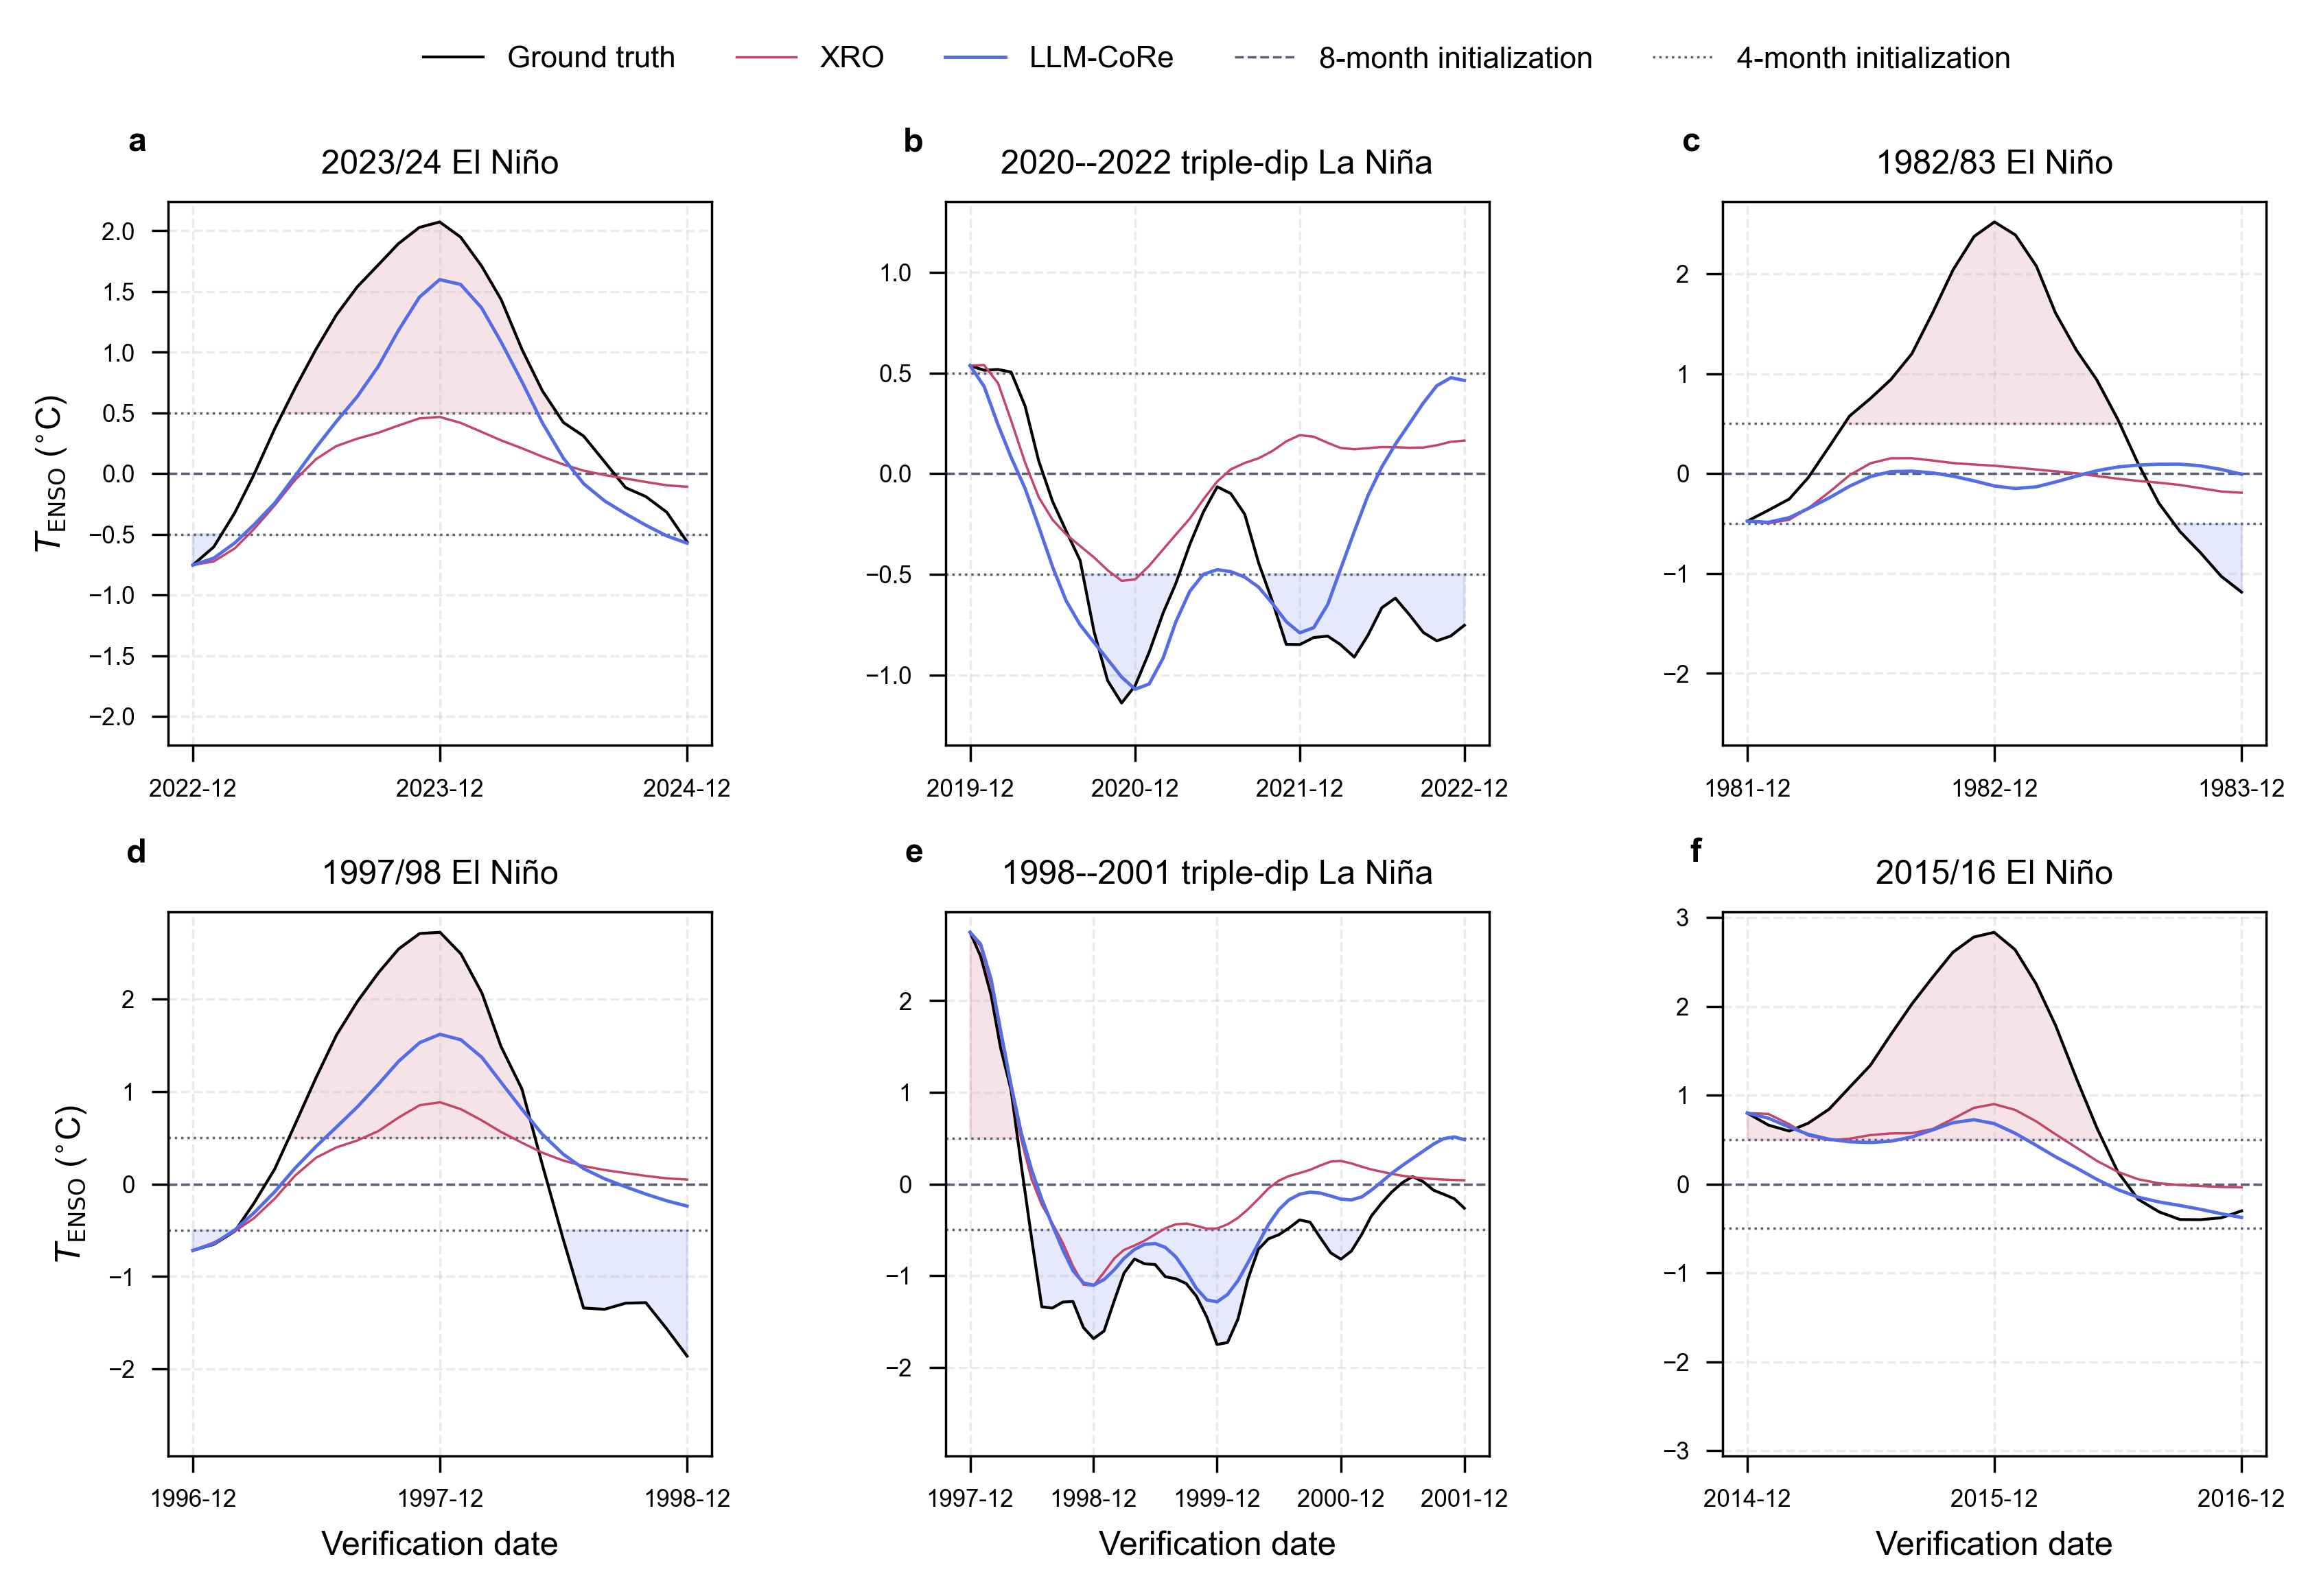

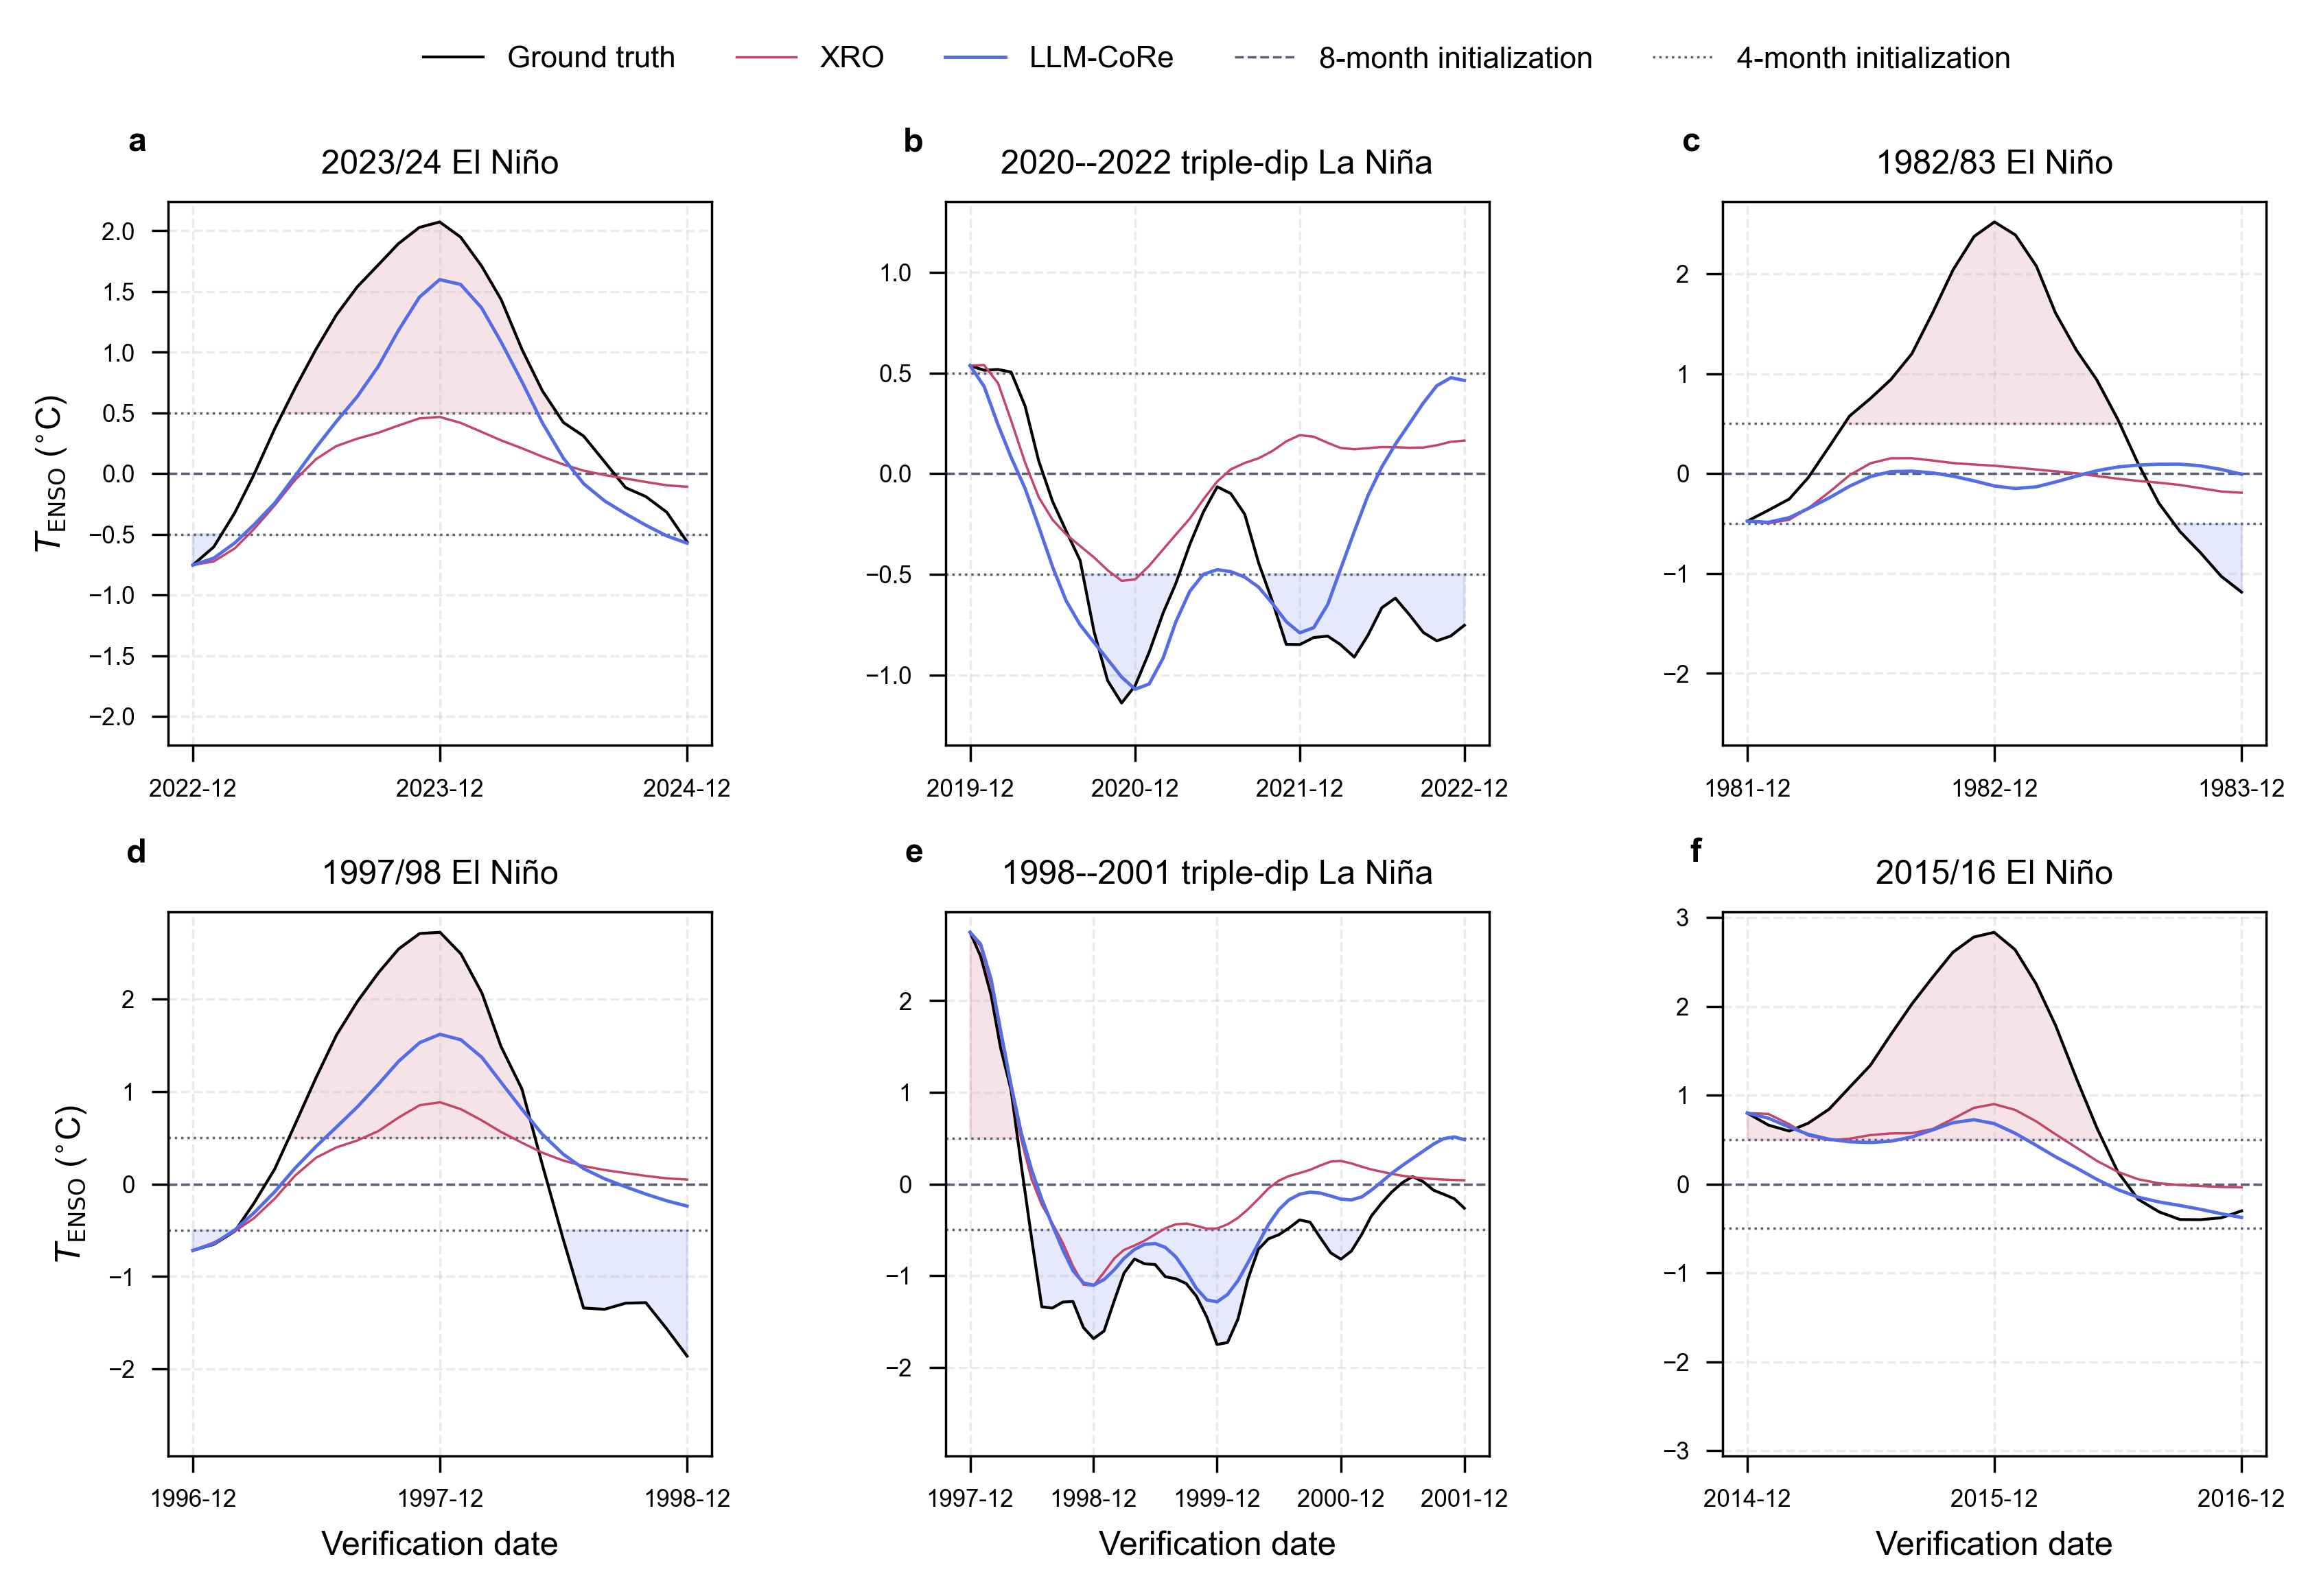

In [5]:
fi, fig, axes = get_fig(
    2, 3, FW=18, A_ratio=1, LM=5, RM=5, TM=5, BM=5,
    HS=7, VS=5, dpi=500, lw=0.5, fontsize=7,
)
axes_flat = np.ravel(axes)
forecast_cache = {}

for panel, (ax, case) in enumerate(zip(axes_flat, cases)):
    train = event_train(case)
    ours = fit_individual(plain_triplet, train)
    xro = assistant.load_baseline_indiv()
    xro.dynamics, _ = est.evaluator.fitter.fit_parameters(xro.dynamics, train, nonlinear=False)
    pred_ours = rollout(ours.dynamics, case['start'], case['months'])
    pred_xro = rollout(xro.dynamics, case['start'], case['months'])
    stop = pred_ours.index.get_level_values('time') + pred_ours.index.get_level_values('lead')
    ours_t = pd.Series(pred_ours[('x', 'ENSO')].values, index=stop)
    xro_t = pd.Series(pred_xro[('x', 'ENSO')].values, index=stop)
    obs = df_all.loc[stop, ('x', 'ENSO')].rolling(3, center=True, min_periods=3).mean()
    obs = obs.fillna(df_all.loc[stop, ('x', 'ENSO')])
    forecast_cache[case['start']] = (ours_t, xro_t, obs)
    dates = stop.to_timestamp()

    ax.plot(dates, obs.values, color='black', lw=1.2*fi['lw'], label='Ground truth', zorder=5)
    ax.plot(dates, xro_t.values, color='#c44569', lw=fi['lw'], label='XRO', zorder=6)
    ax.plot(dates, ours_t.values, color='#546de5', lw=1.4*fi['lw'], label='LLM-CoRe', zorder=7)
    if case['start'] in ['1981-12', '2014-12']:
        event_year = pd.Period(case['start'], freq='M').year + 1
        panel_end = pd.Period(case['start'], freq='M') + case['months']
        # for short_month, linestyle in [(4, '--'), (8, ':')]:
        #     short_start = f'{event_year}-{short_month:02d}'
        #     short_months = panel_end.ordinal - pd.Period(short_start, freq='M').ordinal
        #     short_ours = rollout(ours.dynamics, short_start, short_months)
        #     short_xro = rollout(xro.dynamics, short_start, short_months)
        #     short_stop = short_ours.index.get_level_values('time') + short_ours.index.get_level_values('lead')
        #     short_dates = short_stop.to_timestamp()
        #     ax.plot(short_dates, short_xro[('x', 'ENSO')].values, color='#c44569',
        #             lw=fi['lw'], ls=linestyle, zorder=8)
        #     ax.plot(short_dates, short_ours[('x', 'ENSO')].values, color='#546de5',
        #             lw=1.4*fi['lw'], ls=linestyle, zorder=9)
    ax.fill_between(dates, 0.5, obs.values, where=obs.values > 0.5,
                    color='#c44569', alpha=0.15, interpolate=True)
    ax.fill_between(dates, obs.values, -0.5, where=obs.values < -0.5,
                    color='#546de5', alpha=0.15, interpolate=True)
    for y, ls in [(0, '--'), (0.5, ':'), (-0.5, ':')]:
        ax.axhline(y, color='#596275', lw=fi['lw'], ls=ls)
    ax.set_title(case['title'])
    ax.set_xlabel('Verification date' if panel >= 3 else '')
    ax.set_ylabel(r'$T_{\mathrm{ENSO}}$ ($^{\circ}$C)' if panel % 3 == 0 else '')
    december_ticks = dates[dates.month == 12]
    ax.set_xticks(december_ticks)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=0)
    ax.grid(alpha=0.25, linestyle='--', linewidth=fi['lw'])
    lim = max(1.25, np.nanmax(np.abs(np.r_[obs.values, ours_t.values, xro_t.values])))
    ax.set_ylim(-1.08*lim, 1.08*lim)
    ax.text(-0.04, 1.08, 'abcdef'[panel], transform=ax.transAxes, va='bottom', ha='right',
            fontweight='bold', fontsize=fi['fontsize'], clip_on=False)

from matplotlib.lines import Line2D
handles, labels = axes_flat[0].get_legend_handles_labels()
handles += [
    Line2D([0], [0], color='#596275', lw=fi['lw'], ls='--', label='8-month initialization'),
    Line2D([0], [0], color='#596275', lw=fi['lw'], ls=':', label='4-month initialization'),
]
labels += ['8-month initialization', '4-month initialization']
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.01),
           ncol=5, frameon=False, fontsize=0.9*fi['fontsize'])
for suffix in ['pdf', 'png', 'svg']:
    fig.savefig(save_path / f'Fig3g.{suffix}',
                dpi=600, transparent=True, bbox_inches='tight')
display(fig)



## Fixed-trajectory component diagnostics

Candidate events are screened below before selecting the clearest warm- and cold-event mechanisms for the manuscript figure.


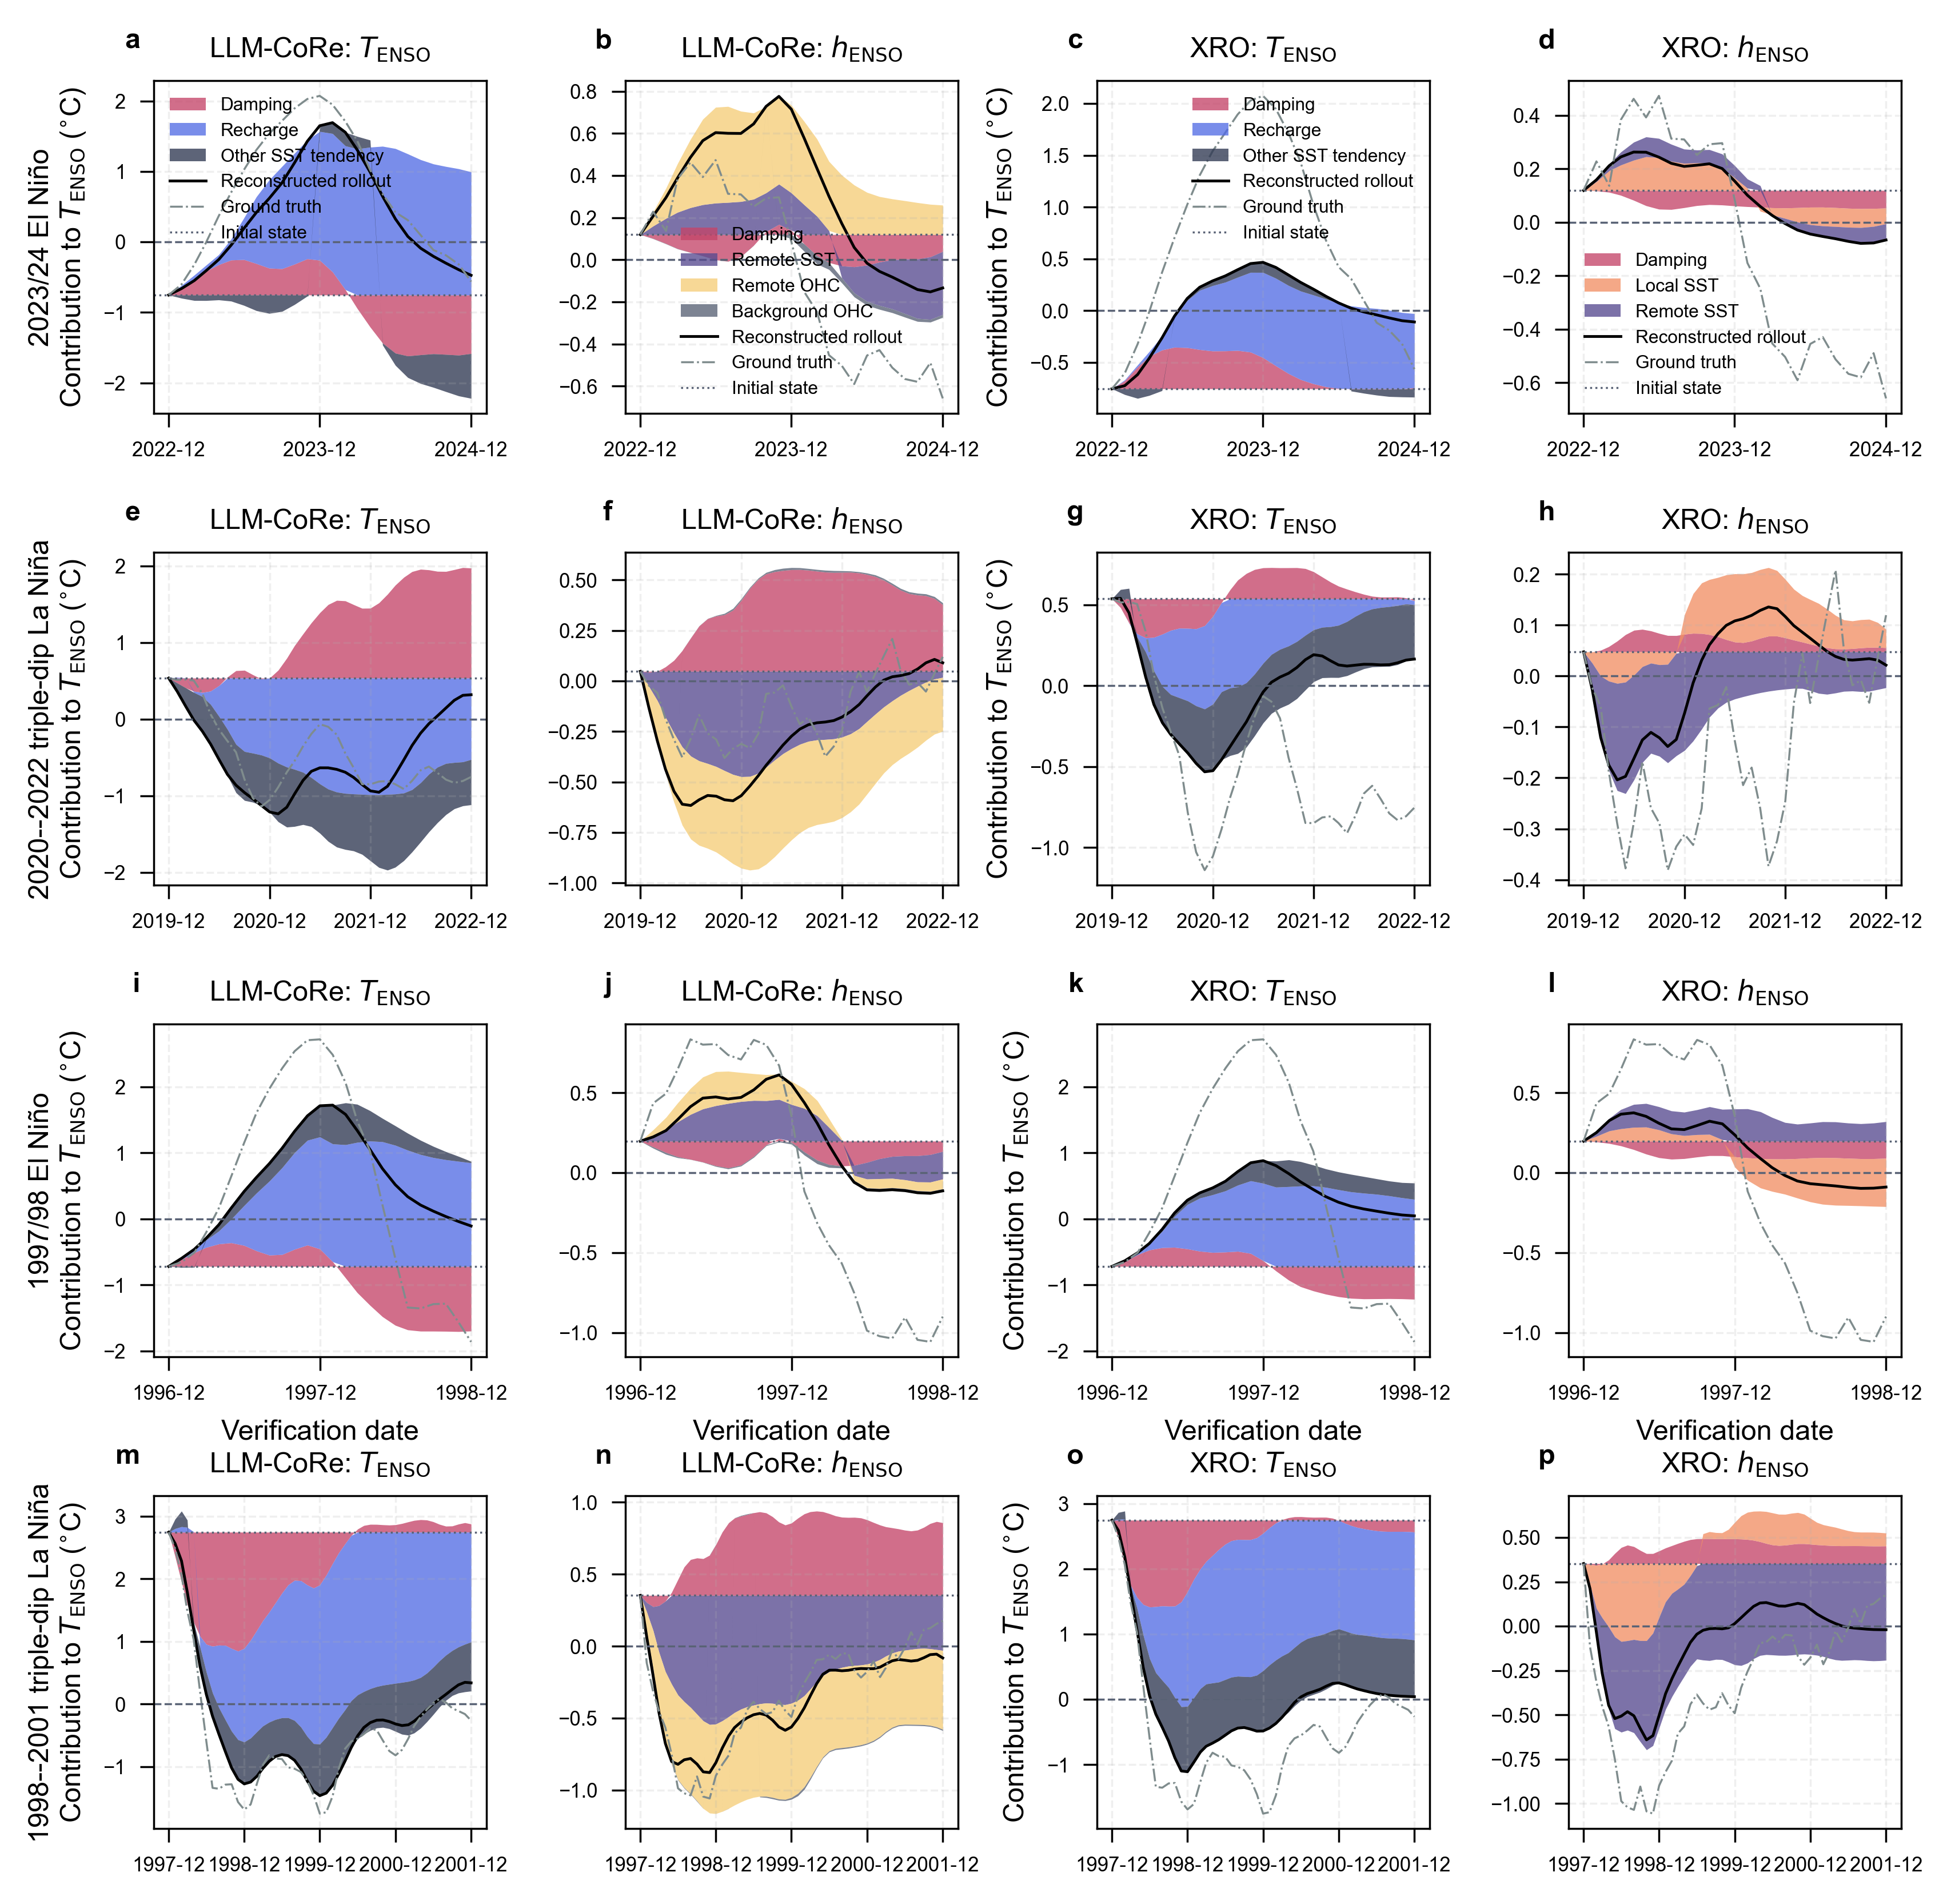

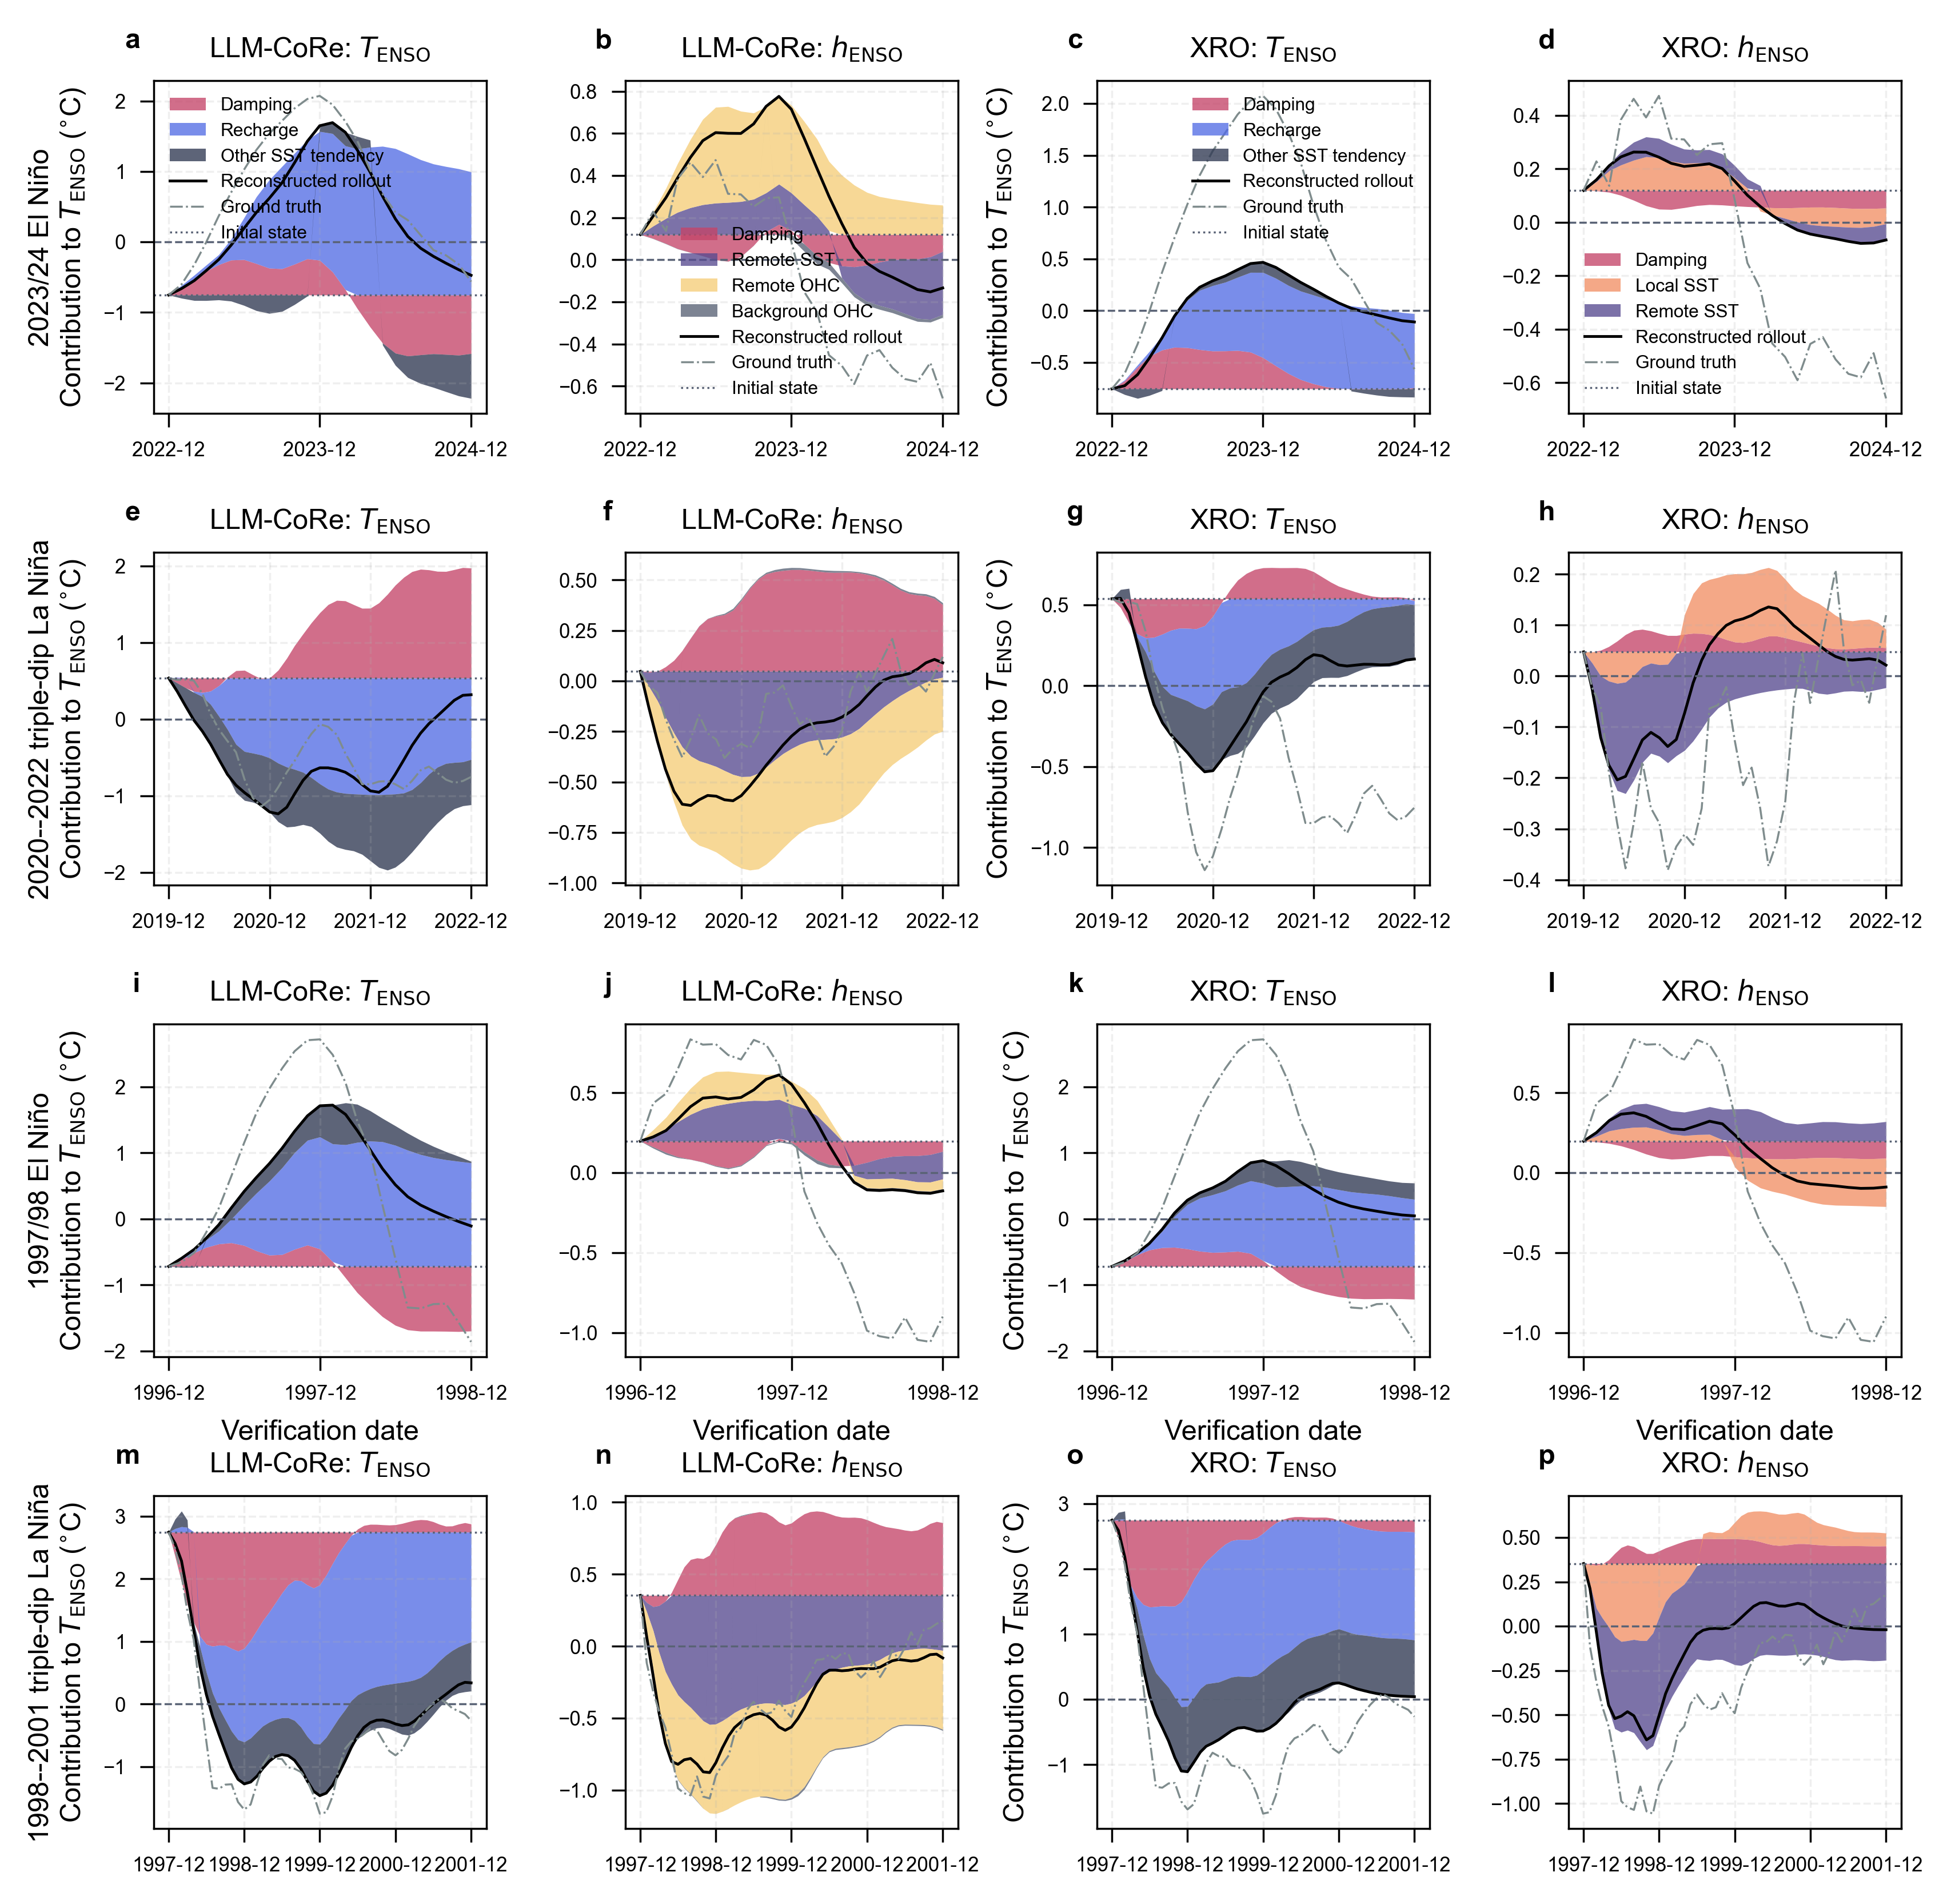

In [ ]:
flags = [
    'damping_flag', 'recharging_flag', 'co2_flag', 'sst_to_sst_flag',
    'ohc_to_sst_flag', 'sst_to_ohc_flag', 'ohc_to_ohc_flag', 'Tbar_flag',
    'other_sst_flag', 'local_sst_flag',
]
for flag in flags:
    df_all[(flag, 'value')] = 1.0
group_specs = {
    'x': [
        ('Damping', ['damping_flag'], '#c44569'),
        ('Recharge', ['recharging_flag'], '#546de5'),
        ('Other SST tendency', ['co2_flag', 'sst_to_sst_flag', 'ohc_to_sst_flag'], '#303952'),
    ],
    'h': [
        ('Damping', ['damping_flag'], '#c44569'),
        ('Remote SST', ['sst_to_ohc_flag'], '#574b90'),
        ('Remote OHC', ['ohc_to_ohc_flag'], '#f5cd79'),
        ('Background OHC', ['Tbar_flag'], '#596275'),
    ],
}
xro_group_specs = {
    'x': [
        ('Damping', ['damping_flag'], '#c44569'),
        ('Recharge', ['recharging_flag'], '#546de5'),
        ('Other SST tendency', ['other_sst_flag'], '#303952'),
    ],
    'h': [
        ('Damping', ['damping_flag'], '#c44569'),
        ('Local SST', ['local_sst_flag'], '#f19066'),
        ('Remote SST', ['sst_to_ohc_flag'], '#574b90'),
    ],
}

def component_decomposition(start, months, withhold=None):
    case = {'start': start}
    if withhold is not None:
        case['withhold'] = withhold
    train = event_train(case)
    model = fit_individual(flagged_triplet, train)
    full = rollout(model.dynamics, start, months)
    stop = full.index.get_level_values('time') + full.index.get_level_values('lead')
    state = full.set_index(stop)
    forcing = df_all.drop(['t', 'x', 'h'], axis=1, level=0)
    dt = df_all['t'].diff().iloc[1].value
    out = {}
    for var in ['x', 'h']:
        tendencies = {}
        for label, enabled, color in group_specs[var]:
            eval_df = state.merge(forcing, left_index=True, right_index=True)
            for flag in flags:
                eval_df[(flag, 'value')] = float(flag in enabled)
            expression = model.dynamics.ddt_sst if var == 'x' else model.dynamics.ddt_wwv
            values = expression.eval(eval_df, edge_list=edge_list, num_nodes=num_nodes)
            tendencies[label] = values[:, assistant.modes.index('ENSO')]
        tendency = pd.DataFrame(tendencies, index=stop)
        cumulative = tendency.shift(1).fillna(0).cumsum() * dt
        baseline = full[(var, 'ENSO')].iloc[0]
        reconstruction = baseline + cumulative.sum(axis=1)
        observation = df_all.loc[stop, (var, 'ENSO')]
        if var == 'x':
            observation = observation.rolling(3, center=True, min_periods=3).mean().fillna(observation)
        out[var] = (baseline, cumulative, reconstruction, observation)
    return out

def xro_component_decomposition(start, months, withhold=None):
    # Fit and roll out the original XRO equations used in the forecast figure.
    # Components are split only after fitting, so their sum is exactly the same fitted model.
    case = {'start': start}
    if withhold is not None:
        case['withhold'] = withhold
    train = event_train(case)
    model = assistant.load_baseline_indiv()
    model.dynamics, _ = est.evaluator.fitter.fit_parameters(model.dynamics, train, nonlinear=False)
    full = rollout(model.dynamics, start, months)
    stop = full.index.get_level_values('time') + full.index.get_level_values('lead')
    state = full.set_index(stop)
    forcing = df_all.drop(['t', 'x', 'h'], axis=1, level=0)
    eval_df = state.merge(forcing, left_index=True, right_index=True)
    dt = df_all['t'].diff().iloc[1].value
    # XRO has five seasonal coefficient bases for each structural term.
    # SST groups: x; readout(ENSO*h); four remaining SST terms.
    # OHC groups: h; local x; aggr(sour(x)).
    fitted_items = {
        'x': model.dynamics.ddt_sst.split_by_add(),
        'h': model.dynamics.ddt_wwv.split_by_add(),
    }
    item_groups = {
        'x': [('Damping', slice(0, 5)), ('Recharge', slice(5, 10)),
              ('Other SST tendency', slice(10, None))],
        'h': [('Damping', slice(0, 5)), ('Local SST', slice(5, 10)),
              ('Remote SST', slice(10, None))],
    }
    assert len(fitted_items['x']) == 30 and len(fitted_items['h']) == 15
    # Repeat the simulator's ten Euler substeps and monthly substep averaging,
    # while accumulating each fitted structural group at every substep.
    from src.utils import df2dict
    initial = df_all.loc[[pd.Period(start, freq='M')]]
    forcing_df = initial.drop(columns=['x', 'h', 't'], level=0)
    X = df2dict(initial[['x', 'h', 't']], keep_shape=True)
    X.update(df2dict(forcing_df, keep_shape=False))
    sub_dt = dt / args.n_steps
    cumulative_state = {
        var: {label: np.zeros_like(X[var]) for label, _ in item_groups[var]}
        for var in ['x', 'h']
    }
    saved = {var: {label: [np.zeros_like(X[var])] for label, _ in item_groups[var]}
             for var in ['x', 'h']}
    for lead in range(1, months + 1):
        monthly_avg = {var: {label: np.zeros_like(X[var]) for label, _ in item_groups[var]}
                       for var in ['x', 'h']}
        for _ in range(args.n_steps):
            total_step = {}
            for var in ['x', 'h']:
                group_steps = {}
                for label, item_slice in item_groups[var]:
                    group_steps[label] = sub_dt * sum(
                        item.eval(X, edge_list=edge_list, num_nodes=num_nodes)
                        for item in fitted_items[var][item_slice]
                    )
                    cumulative_state[var][label] += group_steps[label]
                total_step[var] = sum(group_steps.values())
            X['x'] += total_step['x']
            X['h'] += total_step['h']
            if args.update_t_within_step:
                X['t'] += sub_dt
            for var in ['x', 'h']:
                for label, _ in item_groups[var]:
                    monthly_avg[var][label] += cumulative_state[var][label]
        if not args.update_t_within_step:
            X['t'] += dt
        for var in ['x', 'h']:
            for label, _ in item_groups[var]:
                saved[var][label].append(monthly_avg[var][label] / args.n_steps)
    out = {}
    for var in ['x', 'h']:
        cumulative = pd.DataFrame(
            {label: np.concatenate(saved[var][label], axis=0)[:, assistant.modes.index('ENSO')]
             for label, _ in item_groups[var]},
            index=stop,
        )
        baseline = full[(var, 'ENSO')].iloc[0]
        reconstruction = baseline + cumulative.sum(axis=1)
        rollout_values = full[(var, 'ENSO')].to_numpy()
        np.testing.assert_allclose(reconstruction.to_numpy(), rollout_values, atol=1e-8, rtol=1e-8)
        observation = df_all.loc[stop, (var, 'ENSO')]
        if var == 'x':
            observation = observation.rolling(3, center=True, min_periods=3).mean().fillna(observation)
        out[var] = (baseline, cumulative, reconstruction, observation)
    return out

def signed_stack(ax, dates, baseline, cumulative, specs):
    positive = np.full(len(dates), baseline, dtype=float)
    negative = np.full(len(dates), baseline, dtype=float)
    for label, _, color in specs:
        values = cumulative[label].values
        bottom = np.where(values >= 0, positive, negative)
        top = bottom + values
        ax.fill_between(dates, bottom, top, color=color, alpha=0.78, linewidth=0, label=label)
        positive = np.where(values >= 0, top, positive)
        negative = np.where(values < 0, top, negative)

# Screen all six representative cases before selecting the manuscript examples.
candidate_diagnostic_cases = [
    ('2022-12', 24, '2023/24 El Niño', None),
    ('2019-12', 36, '2020--2022 triple-dip La Niña', None),
    ('1981-12', 24, '1982/83 El Niño', None),
    ('1996-12', 24, '1997/98 El Niño', None),
    ('1997-12', 48, '1998--2001 triple-dip La Niña', ('1997-01', '2001-12')),
    ('2014-12', 24, '2015/16 El Niño', None),
]
component_cache = {}
for start_case, months, _, withhold in candidate_diagnostic_cases:
    component_cache[start_case] = component_decomposition(start_case, months, withhold)

# The final figure shows one warm-event diagnosis and two prolonged cold-event cases.
diagnostic_cases = [
    ('2022-12', 24, '2023/24 El Niño', None),
    ('2019-12', 36, '2020--2022 triple-dip La Niña', None),
    ('1996-12', 24, '1997/98 El Niño', None),
    ('1997-12', 48, '1998--2001 triple-dip La Niña', ('1997-01', '2001-12')),
]
fi, fig, axes = get_fig(
    4, 4, FW=18, A_ratio=1, LM=5, RM=5, TM=5, BM=5,
    HS=5, VS=5, dpi=500, lw=0.5, fontsize=7,
)
axes = np.asarray(axes).reshape(4, 4)

for row, (start, months, event_title, withhold) in enumerate(diagnostic_cases):
    ours_result = component_cache[start]
    xro_result = xro_component_decomposition(start, months, withhold)
    panel_specs = [
        ('LLM-CoRe', 'x', ours_result, group_specs),
        ('LLM-CoRe', 'h', ours_result, group_specs),
        ('XRO', 'x', xro_result, xro_group_specs),
        ('XRO', 'h', xro_result, xro_group_specs),
    ]
    for col, (model_name, var, result, specs) in enumerate(panel_specs):
        ax = axes[row, col]
        baseline, cumulative, reconstruction, observation = result[var]
        dates = cumulative.index.to_timestamp()
        signed_stack(ax, dates, baseline, cumulative, specs[var])
        ax.plot(dates, reconstruction, color='black', lw=1.4*fi['lw'], label='Reconstructed rollout')
        ax.plot(dates, observation.values, color='#7f8c8d', lw=fi['lw'], ls='-.', label='Ground truth')
        ax.axhline(baseline, color='#596275', lw=fi['lw'], ls=':', label='Initial state')
        ax.axhline(0, color='#596275', lw=fi['lw'], ls='--')
        variable_label = r'$T_{\mathrm{ENSO}}$' if var == 'x' else r'$h_{\mathrm{ENSO}}$'
        ax.set_title(f'{model_name}: ' + variable_label)
        ax.set_xlabel('Verification date' if row == 2 else '')
        ylabel = (event_title + '\n' if col == 0 else '')
        ylabel += (r'Contribution to $T_{\mathrm{ENSO}}$' if var == 'x' else
                    r'Contribution to $h_{\mathrm{ENSO}}$') + r' ($^{\circ}$C)'
        ax.set_ylabel(ylabel if col in [0, 2] else '')
        december_ticks = dates[dates.month == 12]
        ax.set_xticks(december_ticks)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.tick_params(axis='x', rotation=0)
        ax.grid(alpha=0.2, linestyle='--', linewidth=fi['lw'])
        ax.text(-0.04, 1.08, 'abcdefghijklmnop'[row*4+col], transform=ax.transAxes, va='bottom', ha='right',
                fontweight='bold', fontsize=fi['fontsize'], clip_on=False)
        if row == 0:
            ax.legend(frameon=False, fontsize=0.65*fi['fontsize'], loc='best')

fig.savefig(save_path / f'Fig3h.pdf', dpi=600, transparent=True, bbox_inches='tight')
fig.savefig(save_path / f'Fig3h.png', dpi=600, transparent=True, bbox_inches='tight')
fig.savefig(save_path / f'Fig3h.svg', dpi=600, transparent=True, bbox_inches='tight')
display(fig)
